All configuration and model checks passed.
Layer depths = [   0. 5000.]
Number of points per layer along Z = [125]
Spacing in each layer in meters = [39.85153559 42.19409283]
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output fo

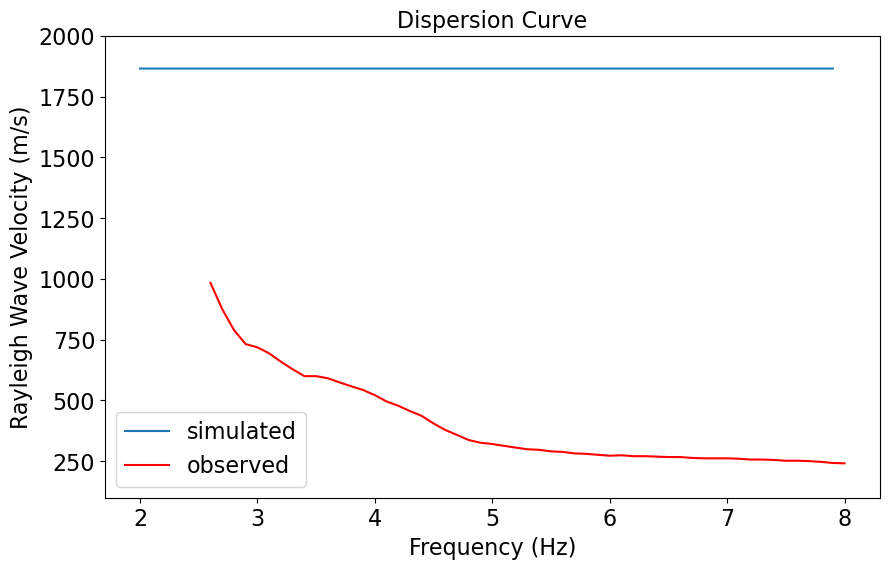

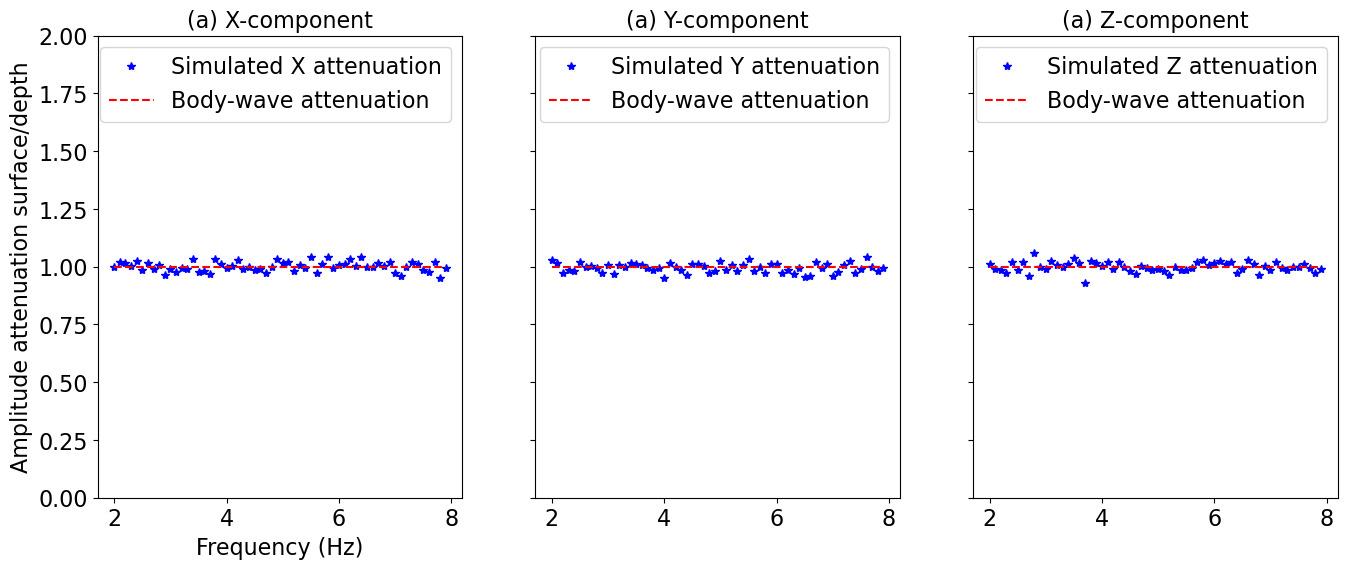

In [ ]:
# script for estimnating the attenuation between two points 
# one on the surface and one underground
# can be applied to real seismic field in layered or homogeneous medium
# and pure body wave or Rayleigh wave field in homogeneous medium
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.io import loadmat

from pysurf96 import surf96
from modules import configLoader
from modules import validateInputs
from modules import createDB
from modules import gfLoader
from modules import simDisp
from modules import plotUtils

def main():

    # load the config file different cases
    # stochastic body wave field in homogeneous half-space 
    configFile="/home/koley/CavityResults/SphAttnTutorialConfig/configParseAttnBodyHomo.ini"
    # stochastic Rayleigh wavefield in homogeneous half-space
    #configFile="/home/koley/CavityResults/SphAttnTutorialConfig/configParseAttnRayHomo.ini"
    
    # stochastic real seismic field in homogeneous half-space, ring source geometry
    #configFile="/home/koley/CavityResults/SphAttnTutorialConfig/configParseAttnRingHomo.ini"
    # stochastic real seismic field in homogeneous half-space, internal source geometry
    #configFile="/home/koley/CavityResults/SphAttnTutorialConfig/configParseAttnInternalHomo.ini"
    
    # stochastic real seismic field in a layered half-space, internal source distribution, might match Terziet attn, but not dispersion
    #configFile="/home/koley/CavityResults/SphAttnTutorialConfig/configParseAttnInternalLayered.ini"
    # stochastic real seismic field in a layered half-space, ring source distribution, might match Terziet attn, but not dispersion
    #configFile="/home/koley/CavityResults/SphAttnTutorialConfig/configParseAttnRingLayered.ini"

    config = configLoader.load_config(configFile)
    validateInputs.validateInputs(config)

    # two depth points
    zList = np.array((0.0, 250.0))
    # generate the two points between which CC will be computed
    gridX = np.array((0.0,))
    gridY = np.array((0.0,))
    
    # database generation strictly not necesary for body and Rayleigh wavefields
    # database geeneration needs to to be done for full-field
    if(config.ifFullField):
        splitAll = createDB.createFinalInputsTD(config,zList)    
        print(f"Prepared {splitAll.shape[0]} total runs")
        print(f"Cores available: {config.cpuCoresQseis}")
    
        results = createDB.runMultiQseis(splitAll, config.inputPath, config.qseisExe, nWorkers = config.cpuCoresQseis)
        
        print("Database generation complete")
        onlySplitAll = False
    else:
        splitAll = createDB.createFinalInputs(config)
        onlySplitAll = True
    
    # flag for pure Rayleigh wavefield in homogeneous half-space
    ifRay = config.ifRay

    # flag for plane P and S waves in homogeneous half space
    ifBody = config.ifBody

    # flag for wavefield simulation
    ifFullField = config.ifFullField

    saveHV = config.saveHV

    thickness = config.thickness # units in meters
    vs = config.vS # units in m/s
    vp = config.vP # units in m/s
    rho = config.rho # units in kg/m^3
    fMin = config.fMin; fMax = config.fMax; df = config.df;# units in Hz
    
    # given a cuboidal domain should be greater than sqrt of 
    xMaxGF = config.xMaxGF # maximum horizontal offset upto which displacements will be used
    zMaxGF = config.zMaxGF # maximum depth upto which displacements will be used
    maxRec = config.maxRec # same value of number of receivers that qseis can handle in one go check qsglobal.h
    xCenter = config.xCenter; yCenter = config.yCenter
    xMin = xCenter-config.xExtent; xMax = xCenter+config.xExtent # minimum and maximum of the simulation domain in X-direction (EW)
    yMin = yCenter-config.yExtent; yMax = yCenter+config.yExtent # maximum and minimum of the simulation domain in Y-direction (NS)
    zMin = 0.0; zMax = config.zExtent # maximum and minimum of the simulation domain in Z-direction (depth)

    itmAC = config.itmAC
    itmACUse = itmAC.copy(); itmACUse[2] = -np.abs(itmACUse[2])
    itmAll = np.vstack((itmACUse,))
    
    # some other inputs for simDisp
    maxRec = config.maxRec; # same value of number of receivers that qseis can handle in one go check qsglobal.h
    tMax = config.tMax; nSamp = config.nSamp
    
    # specify the folder where you want to write all input files, should have rw access
    # fInpPath is the path where the Green's function database exists
    fInpPath = config.inputPath #like "/data/gravwav/koley/QseisInpN/"
    #fInpPath = "/data/gravwav/koley/SALVUSOut/"

    # outDispPath should have rw access and is used for saving temp displacementy files
    outDispPath = config.outDispPath # like "/data/gravwav/koley/OutDisp/"

    # GF components to be used
    components = ['fh-2.tz', 'fh-2.tr', 'fh-2.tt', 'fz-2.tz', 'fz-2.tr']

    # splitAll is necessary so load it
    nRea = config.nRea # number of realizations
    nRea = 1000
    # this file is created at the time of database generation
    splitFileName = fInpPath + 'splitAll.mat'
    splitMat = loadmat(splitFileName)
    splitAll = splitMat['splitAll']

    # source distribution parameters
    R1 = config.R1; R2 = config.R2
    print(config.srcDistri)
    print(config.R1); print(config.R2)
    nSrc = config.nSrc
    srcDistri = config.srcDistri
    scaleVH = config.scaleVH
    # flag if NN is computed directly without writing the displacemnet field
    onFlyNN = config.onFlyNN 

    # number of CPUs to be used for displacement and NN simulation
    nCPUDisp = config.cpuCoresDisp
    computeStrategy = config.computeStrategy

    # frequency axis to be used by simDisp  
    freqOut, idxFreq, df_native = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)
    nFreq = len(freqOut)

    splitAllNew = gfLoader.assembleQseisRuns(splitAll, fInpPath, components, outPath=None, fIndices=idxFreq, onlySplitAll=onlySplitAll, minVel=100.0)
    
    # in case only Rayleigh waves in homogeneous half space is used, Rayleigh wave phase velocity is needed
    if(ifRay):
        periods = 1/freqOut
        vR = surf96(thickness,vp,vs,rho,periods,wave="rayleigh",mode=1,velocity="phase",flat_earth=True)
    else:
        vR = None
    
    # prepare containers
    dispSurfAllRea = np.zeros((nFreq,3))
    dispDepthAllRea = np.zeros((nFreq,3))
    attnZObs = np.zeros((nFreq,3), dtype=np.float64)
    attnXObs = np.zeros((nFreq,3), dtype=np.float64)
    attnYObs = np.zeros((nFreq,3), dtype=np.float64)

    for reaNo in range(0,nRea):
        print('Doing realization = ' +str(reaNo))
        # get the source distribution per realization
        xSrc, ySrc, azSrc, srcMeta =  simDisp.genAmbSrc(nSrc , mode = srcDistri, R1 = R1, R2 = R2, xMin=xMin, xMax=xMax, yMin=yMin,
                                           yMax=yMax, randomPhase=True, freqDependent=True, nFreq=nFreq, decoupledHV=config.decoupledHV,
                                           scaleVH = scaleVH)
        
        # in case the body wave in homogeneous half-space flag is turned on
        if(ifBody):
            metaBody = simDisp.genBodySrc(nSrc, nFreq, eP = 1/3, eS = 2/3)       
        else:
            metaBody=None
        
        if(ifBody):
            dispTempSurf = simDisp.computeFullBodyDisp_parallel(zList[0], gridX, gridY, nSrc, freqOut, vp[0], vs[0], metaBody,
                                 n_workers=nCPUDisp)
            dispTempDepth = simDisp.computeFullBodyDisp_parallel(-zList[1], gridX, gridY, nSrc, freqOut, vp[0], vs[0], metaBody,
                                 n_workers=nCPUDisp)
        elif(ifRay):
            dispTempSurf = simDisp.computeRayleighDisp(zList[0], gridX, gridY, nSrc, freqOut, azSrc,
                                                    srcMeta["phiV"], srcMeta["ampV"], vR, vp[0], vs[0])
            dispTempDepth = simDisp.computeRayleighDisp(-zList[1], gridX, gridY, nSrc, freqOut, azSrc,
                                                    srcMeta["phiV"], srcMeta["ampV"], vR, vp[0], vs[0])
        else:
            # fullfield case
            dispTempSurf, _, _, shmPathsSurf = simDisp.computeFullDispF(zList[0], gridX, gridY, itmAll, xSrc, ySrc, azSrc, srcMeta,idxFreq, freqOut, outDispPath,
                         splitAllNew, xMaxGF, fInpPath, nCPU=nCPUDisp, nChunk=20000, computeStrategy=computeStrategy,
                         saveHV=False, reduceNN=onFlyNN, nnMode=None, nnMeta=None)
            dispTempDepth, _, _, shmPathsDepth = simDisp.computeFullDispF(zList[1], gridX, gridY, itmAll, xSrc, ySrc, azSrc, srcMeta,idxFreq, freqOut, outDispPath,
                         splitAllNew, xMaxGF, fInpPath, nCPU=nCPUDisp, nChunk=20000, computeStrategy=computeStrategy,
                         saveHV=False, reduceNN=onFlyNN, nnMode=None, nnMeta=None)

        dispSurfAllRea += (np.abs(dispTempSurf[:,0,:]))**2
        dispDepthAllRea += (np.abs(dispTempDepth[:,0,:]))**2

        if(ifFullField):
            del dispTempSurf
            simDisp.cleanup_sharedmem(shmPathsSurf)
            del dispTempDepth
            simDisp.cleanup_sharedmem(shmPathsDepth)
    
    # now get the attenuation
    attnSim = np.sqrt(dispSurfAllRea/dispDepthAllRea)
    dispSurfAllRea = dispSurfAllRea/nRea
    dispDepthAllRea = dispDepthAllRea/nRea

    dispAll = np.hstack((dispSurfAllRea, dispDepthAllRea))

    # load Terziet Attenuation
    terzAttn = loadmat(os.path.join(config.siteASDPath,'attnModel.mat'))
    for i in range(0,3):
        attnXObs[:,i] = np.interp(freqOut,terzAttn['attnE'][:,0],terzAttn['attnE'][:,i+1])
        attnYObs[:,i] = np.interp(freqOut,terzAttn['attnN'][:,0],terzAttn['attnN'][:,i+1])
        attnZObs[:,i] = np.interp(freqOut,terzAttn['attnZ'][:,0],terzAttn['attnZ'][:,i+1])

    # get the theoretical Rayleigh transfer functions to check how it matches when full field
    # for a homogeneous half-space is invoked
    periods = 1/freqOut
    vR = surf96(thickness,vp,vs,rho,periods,wave="rayleigh",mode=1,velocity="phase",flat_earth=True)
    Th, Tz = simDisp.rayleigh_transfer_function(freqOut, vR, vp[0], vs[0], -zList[1])
    # active the plotting routine for consistent fontsizes
    plotUtils.set_plot_style("medium")
    terzDC = loadmat('/home/koley/pySeis1DNNCavity/TERZ/DCTerziet.mat')
    
    fig,ax = plt.subplots(figsize=(10,6))
    ax.plot(freqOut,vR,label='simulated')
    ax.plot(terzDC['dcBigRing'][:,0],terzDC['dcBigRing'][:,1],'r',label='observed')
    ax.set_ylim(100,2000)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Rayleigh Wave Velocity (m/s)')
    ax.set_title('Dispersion Curve')
    ax.legend()

    if(ifFullField):
        figAttn, axAttn = plotUtils.plotAttn(freqOut, attnSim, attnXObs, attnYObs, attnZObs)
    else:
        figAttn, axAttn = plt.subplots(1,3,figsize=(16,6),sharey=True)
        axAttn[0].plot(freqOut,attnSim[:,0],'b*',label='Simulated X attenuation')
        axAttn[1].plot(freqOut,attnSim[:,1],'b*',label='Simulated Y attenuation')
        axAttn[2].plot(freqOut,attnSim[:,2],'b*',label='Simulated Z attenuation')
        axAttn[0].set_ylabel('Amplitude attenuation surface/depth')
        axAttn[0].set_xlabel('Frequency (Hz)')
        axAttn[0].set_title('(a) X-component')
        axAttn[1].set_title('(a) Y-component')
        axAttn[2].set_title('(a) Z-component')
        #axAttn[0].set_ylim()
                                               

    if(ifBody):
        # attenuation should be about 1
        axAttn[0].plot(freqOut,np.ones((len(freqOut),)),'r--',label='Body-wave attenuation')
        axAttn[1].plot(freqOut,np.ones((len(freqOut),)),'r--',label='Body-wave attenuation')
        axAttn[2].plot(freqOut,np.ones((len(freqOut),)),'r--',label='Body-wave attenuation')
        axAttn[0].set_ylim(0,2)
    elif(ifRay):
        axAttn[0].plot(freqOut,1/Th,'r--',label='Rayleigh-wave attenuation')
        axAttn[1].plot(freqOut,1/Th,'r--',label='Rayleigh-wave attenuation')
        axAttn[2].plot(freqOut,1/Tz,'r--',label='Rayleigh-wave attenuation')
    else:
        # Terziet like attenuation, but any layered medium might not
        # # reproduce that, but the example might
        # plotting the 50th percentile
        print(' Comparing with Terziet, might not match')
    
    axAttn[0].legend()
    axAttn[1].legend()
    axAttn[2].legend()

if __name__ == "__main__":
    main()